In [2]:
import pandas as pd, numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")

df = pd.read_csv("Students Performance Dataset 2.csv")
print(df.shape)
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'Students Performance Dataset 2.csv'

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1005 entries, 0 to 1004
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   student_id           1005 non-null   int64  
 1   gender               1005 non-null   object 
 2   school_type          1005 non-null   object 
 3   parental_education   1005 non-null   object 
 4   study_hours_per_day  1005 non-null   float64
 5   attendance_pct       984 non-null    float64
 6   sleep_hours          975 non-null    float64
 7   internet_access      1005 non-null   object 
 8   tutoring             1005 non-null   object 
 9   extracurricular      1005 non-null   object 
 10  math_score           1005 non-null   int64  
 11  reading_score        1005 non-null   int64  
 12  science_score        1005 non-null   int64  
dtypes: float64(3), int64(4), object(6)
memory usage: 102.2+ KB


,student_id,study_hours_per_day,attendance_pct,sleep_hours,math_score,reading_score,science_score
count,1005.000000,1005.000000,984.000000,975.000000,1005.000000,1005.000000,1005.000000
mean,5501.097512,3.567761,85.139228,6.812308,69.497512,69.746269,69.016915
std,288.711205,1.691629,9.543280,1.208590,11.785316,11.550784,11.846155
min,5001.000000,0.000000,53.000000,3.300000,21.000000,37.000000,32.000000
25%,5251.000000,2.400000,79.000000,6.000000,61.000000,62.000000,61.000000
50%,5502.000000,3.500000,86.000000,6.800000,70.000000,69.000000,68.000000
75%,5751.000000,4.700000,92.000000,7.600000,77.000000,77.000000,77.000000
max,6000.000000,9.300000,100.000000,10.000000,100.000000,100.000000,100.000000


In [ ]:
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
df["sleep_hours"] = df["sleep_hours"].fillna(df["sleep_hours"].median())
df["attendance_pct"] = df["attendance_pct"].fillna(df["attendance_pct"].median())
print(df.isna().sum().sum(), df.shape)

student_id              0
gender                  0
school_type             0
parental_education      0
study_hours_per_day     0
attendance_pct         21
sleep_hours            30
internet_access         0
tutoring                0
extracurricular         0
math_score              0
reading_score           0
science_score           0
dtype: int64
Duplicates: 5
0 (1000, 13)


In [ ]:
scores = ["math_score","reading_score","science_score"]
df["average_score"] = df[scores].mean(axis=1).round(1)
df["grade"] = pd.cut(df["average_score"], [-1,59,69,79,89,100], labels=["F","D","C","B","A"])
df["pass"] = df["average_score"] >= 60

df["study_group"] = pd.cut(df["study_hours_per_day"], [-1,2,4,6,24], labels=["0-2h","2-4h","4-6h","6h+"])
df["attendance_group"] = pd.cut(df["attendance_pct"], [0,75,85,95,100], labels=["<75%","75-85%","85-95%","95%+"])
df["sleep_group"] = pd.cut(df["sleep_hours"], [0,6,8,24], labels=["<6h","6-8h","8h+"])

In [ ]:
print(df[scores + ["average_score"]].describe().round(2))
print(f"Pass rate: {df['pass'].mean():.1%}")
print(df["grade"].value_counts().sort_index())

       math_score  reading_score  science_score  average_score
count     1000.00        1000.00        1000.00        1000.00
mean        69.47          69.73          69.02          69.41
std         11.80          11.57          11.87           9.79
min         21.00          37.00          32.00          39.00
25%         61.00          62.00          61.00          62.60
50%         70.00          69.00          68.00          69.30
75%         77.00          77.00          77.00          75.70
max        100.00         100.00         100.00          98.00
Pass rate: 83.3%
grade
F    150
D    349
C    333
B    143
A     25
Name: count, dtype: int64


In [ ]:
cat_cols = ["gender","school_type","parental_education","internet_access","tutoring",
            "extracurricular","study_group","attendance_group","sleep_group"]
for c in cat_cols:
    print(f"\n--- Average score by {c} ---")
    print(df.groupby(c, observed=True)["average_score"].agg(["count","mean","median"]).round(2)
            .sort_values("mean", ascending=False))

gaps = {c: df.groupby(c, observed=True)["average_score"].mean().agg(lambda s: s.max()-s.min()) for c in cat_cols}
pd.Series(gaps).sort_values(ascending=False).round(2)


--- Average score by gender ---
        count   mean  median
gender                      
male      485  69.80    70.0
female    515  69.04    68.3

--- Average score by school_type ---
             count   mean  median
school_type                      
Private        335  73.03    72.3
Public         665  67.58    67.7

--- Average score by parental_education ---
                    count   mean  median
parental_education                      
bachelor's            255  71.56   71.00
master's              122  71.55   72.15
some college          328  68.98   68.70
high school           295  67.13   67.30

--- Average score by internet_access ---
                 count   mean  median
internet_access                      
yes                837  69.68    69.3
no                 163  67.99    68.0

--- Average score by tutoring ---
          count   mean  median
tutoring                      
yes         300  72.15    71.5
no          700  68.23    68.0

--- Average score by extracurric

,0
study_group,24.86
attendance_group,5.65
school_type,5.45
sleep_group,4.63
parental_education,4.43
tutoring,3.92
extracurricular,1.71
internet_access,1.70
gender,0.76


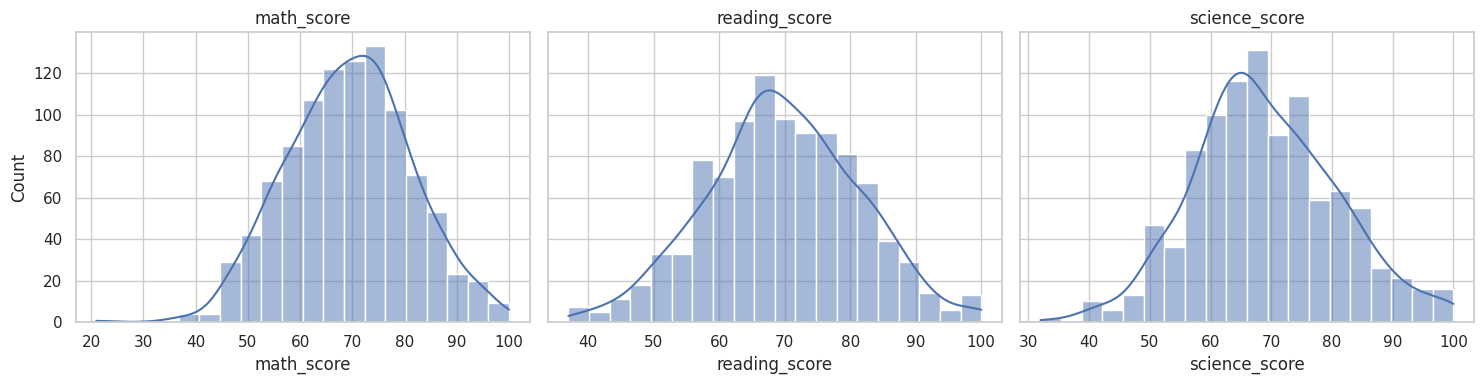

In [ ]:
# Score distributions
fig, axes = plt.subplots(1, 3, figsize=(15,4), sharey=True)
for ax, col in zip(axes, scores):
    sns.histplot(df[col], bins=20, kde=True, ax=ax); ax.set_title(col)
plt.tight_layout(); plt.show()

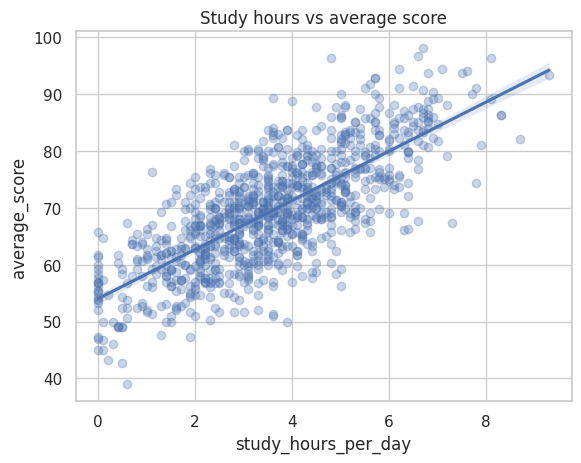

In [ ]:
# NEW: study hours vs score (scatter with trend line)
sns.regplot(data=df, x="study_hours_per_day", y="average_score", scatter_kws={"alpha":0.3})
plt.title("Study hours vs average score"); plt.show()

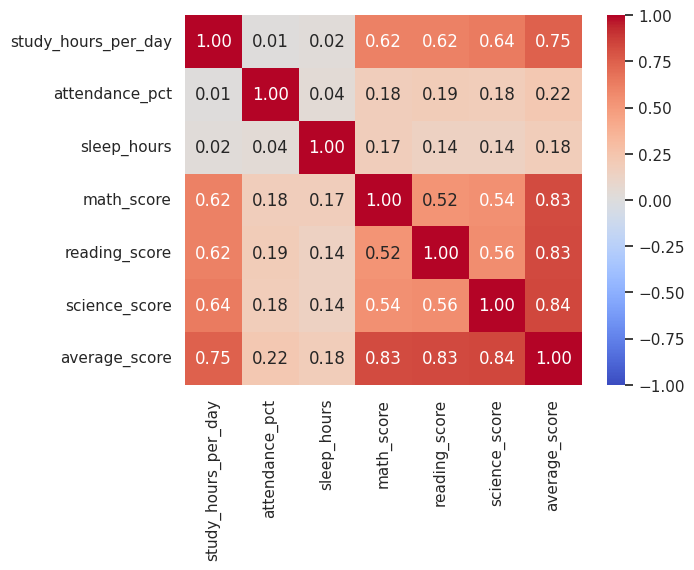

In [ ]:
# NEW: correlation of numeric columns
num = ["study_hours_per_day","attendance_pct","sleep_hours"] + scores + ["average_score"]
sns.heatmap(df[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.show()

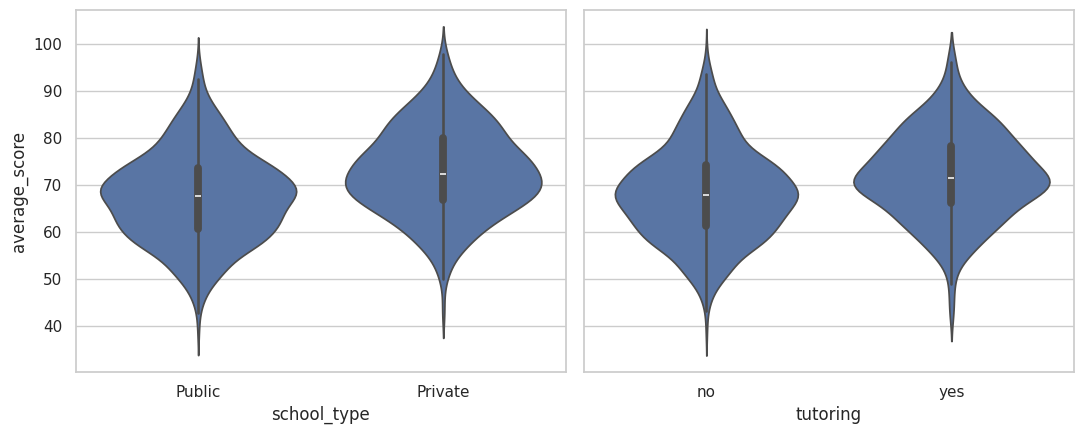

In [ ]:
# School type and tutoring
fig, axes = plt.subplots(1, 2, figsize=(11,4.5), sharey=True)
sns.violinplot(data=df, x="school_type", y="average_score", ax=axes[0])
sns.violinplot(data=df, x="tutoring", y="average_score", ax=axes[1])
plt.tight_layout(); plt.show()

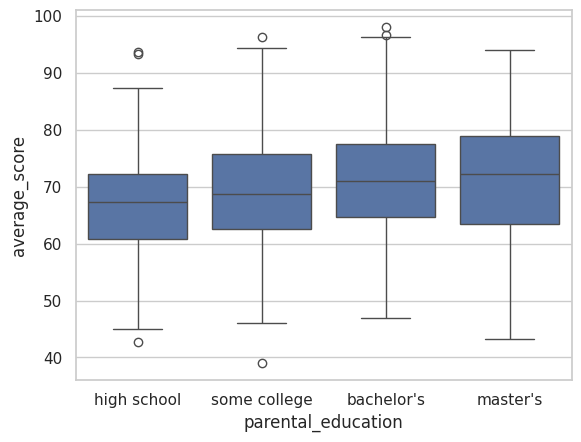

In [ ]:
# Parental education
order = ["high school","some college","bachelor's","master's"]
sns.boxplot(data=df, x="parental_education", y="average_score", order=order)
plt.show()

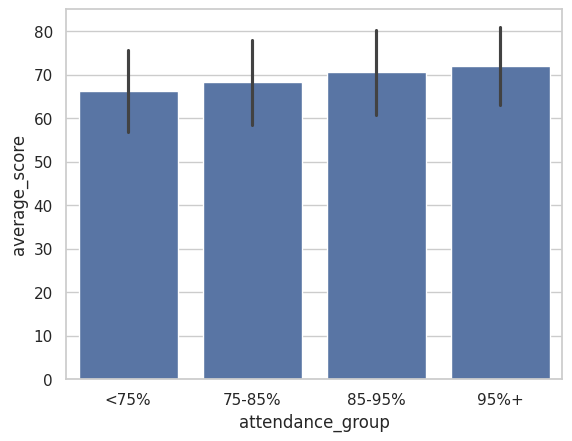

In [ ]:
# Attendance groups
sns.barplot(data=df, x="attendance_group", y="average_score", errorbar="sd")
plt.show()

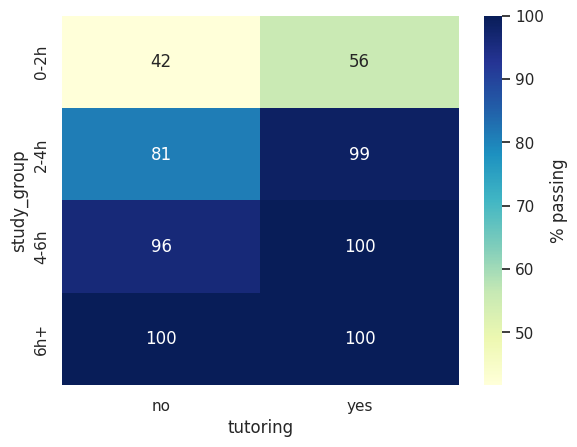

In [ ]:
# Combined: study group x tutoring pass rate
pv = df.pivot_table(index="study_group", columns="tutoring", values="pass", aggfunc="mean", observed=True)*100
sns.heatmap(pv, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label":"% passing"})
plt.show()

In [ ]:
from scipy import stats

# Does tutoring help? (t-test)
a = df[df.tutoring=="yes"]["average_score"]
b = df[df.tutoring=="no"]["average_score"]
print(stats.ttest_ind(a, b), a.mean()-b.mean())

# Is study time linked to score? (Pearson correlation)
r, p = stats.pearsonr(df["study_hours_per_day"], df["average_score"])
print(f"r={r:.2f}, p={p:.2e}")

TtestResult(statistic=np.float64(5.905581328581136), pvalue=np.float64(4.813936682330988e-09), df=np.float64(998.0)) 3.923571428571435
r=0.75, p=2.97e-179


In [ ]:
import statsmodels.formula.api as smf
m = smf.ols("average_score ~ study_hours_per_day + attendance_pct + sleep_hours + C(school_type) + C(parental_education) + C(tutoring)", data=df).fit()
print(m.summary().tables[1])

                                            coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------
Intercept                                29.7380      1.610     18.471      0.000      26.579      32.897
C(school_type)[T.Public]                 -5.2409      0.315    -16.653      0.000      -5.858      -4.623
C(parental_education)[T.high school]     -3.8869      0.401     -9.689      0.000      -4.674      -3.100
C(parental_education)[T.master's]         1.5077      0.517      2.914      0.004       0.492       2.523
C(parental_education)[T.some college]    -1.7378      0.392     -4.429      0.000      -2.508      -0.968
C(tutoring)[T.yes]                        4.2915      0.325     13.225      0.000       3.655       4.928
study_hours_per_day                       4.3143      0.088     49.127      0.000       4.142       4.487
attendance_pct                            0.22

## Conclusion

### Objective
To find out whether student study habits (study hours, attendance, sleep) affect exam scores more than background factors (school type, parental education).

### Method
- Cleaned the data: removed 5 duplicate rows and filled missing sleep hours and attendance values with the median
- Created an average score, a letter grade, a pass/fail flag (average of 60 or above) and grouped versions of study hours, attendance and sleep
- Compared groups with `groupby` summaries and Seaborn visualizations
- Tested relationships with a t-test (tutoring) and a Pearson correlation (study hours)
- Fitted a linear regression to compare all factors together

### Key Findings
1. **Overall performance:** The average score was about 69.4, and about 83% of students passed.
2. **Study hours were the strongest factor.** Average scores rose from about 59 (0-2 hours a day) to about 84 (6+ hours), a gap of nearly 25 points. Study hours and average score were strongly correlated (r = 0.75, p < 0.001).
3. **Background factors mattered, but less.** Private school students averaged 73.0 versus 67.6 for public school (about 5 points). Students whose parents had only high school education averaged 67.1, versus 71.6 for those with a bachelor's or master's degree (about 4.5 points).
4. **Tutoring helped.** Students with tutoring scored about 4 points higher (72.2 vs 68.2), and the t-test showed this was statistically significant (t = 5.91, p < 0.001).
5. **Attendance and sleep had smaller effects.** Students with 95%+ attendance averaged about 5.6 points more than those under 75%, and students who slept 8+ hours averaged about 4.7 points more than those who slept under 6.
6. **Gender made almost no difference** (under 1 point).
7. **Regression result:** With all factors included, each extra hour of daily study was linked to about 4.3 more points. Public school was linked to about 5 fewer points, and tutoring to about 4 more. The model explained about 77% of the variation in scores (R² ≈ 0.77).

### Answer to the Question
In this dataset, study habits, especially daily study time, were associated with larger score differences than background factors such as school type or parental education.

### Limitations
- Correlation does not imply causation. Students who study more may also be more motivated in other ways.
- Study hours and sleep are probably self-reported, which can be inaccurate.
- The dataset has no information on teaching quality, prior grades or learning difficulties.
- Median filling of missing values may slightly understate real variation.

### Next Steps
- Test for interactions, for example whether tutoring helps more for students who study little
- Build a model to predict pass/fail and check which features matter most
- Repeat the analysis on a real-world student dataset

